# Cuevas v2: las cuevas de la Luna y Marte como sitios, con su análogo en la Tierra por tipo y forma

En cuevas_v1 casi ningún sitio tenía una cueva a menos de 50 km: las cuevas están en otros lugares. En v2 **las propias cuevas
son los sitios**, se describe cada una y se busca en la Tierra una cueva **del mismo tipo**:

1. **Tipo** (filtro): tragaluz de tubo de lava, pozo de colapso, fractura, karst en sal, fundido de impacto, tierras altas, entrada lateral.
2. **Forma sin unidades**: profundidad / diámetro del pozo o del colapso. Los tamaños absolutos no se comparan: los tubos de
   Marte son ~100× y los de la Luna ~1000× más anchos que los de la Tierra (Sauro et al. 2020).
3. **Terreno alrededor**: la misma topografía que el resto de sitios (KS de pendiente y relieve, Copernicus en la Tierra).
4. **Temperatura interior**: en la Luna, la medida de Diviner bajo los salientes (Horvath et al. 2022, ~290 K); en la Tierra,
   la temperatura media de la superficie del lugar (una cueva se queda cerca de la media anual).

| Datos | Fuente |
|---|---|
| Pozos de la Luna | LROC Lunar Pit Atlas (Wagner y Robinson 2021) |
| Geometría interna de 6 pozos | Wagner y Robinson 2022 (Zenodo 6622042) |
| Tubo confirmado bajo Mare Tranquillitatis | Carrer et al. 2024 (Mini-RF) |
| Candidatos de Marte | Mars Global Cave Candidate Catalog (Cushing, USGS) |
| Profundidad de pozos atípicos de Marte | PITS (Le Corre et al. 2023, Zenodo 8308454) |
| Forma de los tubos de la Tierra | Pyroduct Digital Catalog v3.0 (Zenodo 23456401) y Sauro et al. 2020 |
| Cuevas análogas de la Tierra | ficha de análogos (con fuente por cueva) |

**Orden de ejecución**
1. Este notebook entero: crea `06_web/sitios_cuevas_v0/sitios_cuevas.geojson` y compara tipo, forma y temperatura.
2. `topografia_sitios_v2` (versión nueva, que añade los sitios-cueva).
3. Este notebook otra vez: la sección 6 añade la topografía.

## 1. Configuración

In [1]:
import os, re, json, glob, zipfile, shutil, datetime, unicodedata, warnings, time, gc
import numpy as np, pandas as pd, requests, geopandas as gpd, rasterio
import matplotlib.pyplot as plt
from rasterio import features
from scipy import ndimage
from shapely.geometry import shape, Point, box
from shapely import affinity
from IPython.display import display
from google.colab import drive
warnings.filterwarnings("ignore", message=".*geographic CRS.*")

drive.mount("/content/drive", force_remount=True)   # vuelve a montar: ve los archivos que otros notebooks acaban de escribir
for raiz in ["/content/drive/MyDrive", "/content/drive/My Drive"]:
    if os.path.isdir(raiz):
        break
BASE = f"{raiz}/Hackathon Nasa"
VERSION = "cuevas_v2"
RES, WEB = f"{BASE}/04_resultados/{VERSION}", f"{BASE}/06_web/{VERSION}"
WEB_SITIOS = f"{BASE}/06_web/sitios_cuevas_v0"
BRUTOS = f"{BASE}/03_datos/brutos/cuevas"
CACHE = f"{BASE}/03_datos/cache_api/cuevas_v2"
TMP = "/content/tmp/cuevas_v2"
for d in (RES, WEB, WEB_SITIOS, BRUTOS, CACHE, TMP):
    os.makedirs(d, exist_ok=True)

DESCARGAR_NUBES = False         # nubes de puntos de 6 pozos lunares (132 MB): su formato no es XYZ simple; las profundidades salen del atlas
MAX_POR_TIPO_MARTE = 8          # sitios-cueva de Marte por tipo
MAX_FUNDIDO_LUNA = 8            # pozos en fundido de impacto (uno por cráter, los más grandes)
UMBRAL_TOPO = 0.2
T_SOMBRA_POZO_K = 290           # Horvath et al. 2022: bajo el saliente, en sombra (medido en Mare Tranquillitatis y Mare Ingenii)
RADIO_CUEVA_TIERRA_KM = 10      # círculo alrededor de cada cueva de la Tierra (como los análogos de topografía)
R_TIERRA = 6371.0

FIGURAS = f"{RES}/figuras"; os.makedirs(FIGURAS, exist_ok=True)
_mostrar = getattr(plt, "_show_original", plt.show); plt._show_original = _mostrar
_n_fig = [0]
def _mostrar_y_guardar(*a, **k):
    fig = plt.gcf()
    if fig.axes:
        _n_fig[0] += 1
        titulo = next((ax.get_title() for ax in fig.axes if ax.get_title()), "figura")
        s = re.sub(r"[^a-zA-Z0-9]+", "_", unicodedata.normalize("NFKD", titulo).encode("ascii", "ignore").decode()).strip("_").lower()[:50]
        fig.savefig(f"{FIGURAS}/fig_{_n_fig[0]:02d}_{s}.png", dpi=80, bbox_inches="tight")
    _mostrar(*a, **k)
plt.show = _mostrar_y_guardar

SESION = requests.Session()
SESION.headers["User-Agent"] = "Mozilla/5.0 (Hackathon NASA Space Apps; Colab)"

def descargar(urls, destino, minimo_bytes=1000, es_zip=False):
    valido = lambda p: os.path.exists(p) and os.path.getsize(p) >= minimo_bytes and (not es_zip or zipfile.is_zipfile(p))
    if valido(destino):
        return destino
    for url in urls:
        try:
            tmp = f"{TMP}/{os.path.basename(destino)}.part"
            with SESION.get(url, stream=True, timeout=900) as r:
                r.raise_for_status()
                with open(tmp, "wb") as f:
                    for trozo in r.iter_content(1 << 22):
                        f.write(trozo)
            if valido(tmp):
                shutil.copy2(tmp, destino); os.remove(tmp)
                print(f"   ✔ {os.path.basename(destino)} ({os.path.getsize(destino) / 1e6:.1f} MB)")
                return destino
            print(f"   ⚠ {url[:80]}: archivo no válido")
        except Exception as e:
            print(f"   ⚠ {url[:80]}: {e!r}"[:200])
    return None

def zenodo(registro, patron, destino_dir=BRUTOS, minimo_bytes=1000):
    """Descarga los archivos de un registro de Zenodo cuyo nombre cumple el patrón (vía la API, con nombre exacto)."""
    rutas = []
    try:
        info = SESION.get(f"https://zenodo.org/api/records/{registro}", timeout=120).json()
        archivos = [(f["key"], f["links"].get("self") or f["links"].get("content")) for f in info.get("files", [])]
    except Exception as e:
        print(f"   ⚠ API de Zenodo ({registro}): {e!r}"[:150]); archivos = []
    for nombre, enlace in archivos:
        if re.search(patron, nombre, re.I):
            urls = [enlace, f"https://zenodo.org/records/{registro}/files/{requests.utils.quote(nombre)}?download=1"]
            r = descargar([u for u in urls if u], f"{destino_dir}/{nombre}", minimo_bytes=minimo_bytes,
                          es_zip=nombre.lower().endswith(".zip"))
            if r:
                rutas.append(r)
    if not rutas:   # sin API: lo que ya esté en Drive
        rutas = [p for p in glob.glob(f"{destino_dir}/*") if re.search(patron, os.path.basename(p), re.I)]
    return rutas

def slug(t):
    return re.sub(r"[^a-z0-9]+", "-", unicodedata.normalize("NFKD", str(t)).encode("ascii", "ignore").decode().lower()).strip("-")[:40]

def km_entre(lat1, lon1, lat2, lon2, R=R_TIERRA):
    la1, lo1, la2, lo2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

def num(s):
    return pd.to_numeric(pd.Series(s).astype(str).str.extract(r"(-?\d+(?:\.\d+)?)")[0], errors="coerce").values

si = lambda s: pd.Series(s).astype(str).str.strip().str.lower().str.match(r"^(y|yes|s[ií]|true|1)").values

Mounted at /content/drive


## 2. Datos
Los dos catálogos de cuevas_v1 ya están en `03_datos/brutos/cuevas/`. Se añaden los de Zenodo: PITS (profundidades de Marte),
Pyroduct (forma de los tubos de la Tierra, 86 MB) y, si `DESCARGAR_NUBES`, las nubes de puntos de 6 pozos lunares (132 MB).

In [2]:
# Luna: catálogo de pozos de LROC (descargado en cuevas_v1)
RUTA_PITS = "LRO-L-LROC-5-RDR-V1.0/LROLRC_2001/EXTRAS/SHAPEFILE/LUNAR_PIT_LOCATIONS/LUNAR_PIT_LOCATIONS.CSV"
ruta = descargar([f"https://pds.lroc.im-ldi.com/data/{RUTA_PITS}", f"https://pds.lroc.asu.edu/data/{RUTA_PITS}"],
                 f"{BRUTOS}/LUNAR_PIT_LOCATIONS.CSV", minimo_bytes=5_000)
pits = pd.read_csv(ruta, encoding="latin-1"); pits.columns = [c.strip() for c in pits.columns]
print(f"Luna: {len(pits)} pozos")

# Marte: catálogo de candidatos (descargado en cuevas_v1)
z = descargar(["https://astrogeology.usgs.gov/ckan/dataset/c2960f77-ee20-4cc6-ac85-abbecc0fc7f6/resource/ccd54fb2-9a50-46bf-8971-80c241bb2f40/download/mars_cave_catalog.zip"],
              f"{BRUTOS}/mars_cave_catalog.zip", minimo_bytes=5_000, es_zip=True)
assert z, f"Falta mars_cave_catalog.zip en {BRUTOS}"
with zipfile.ZipFile(z) as zz:
    zz.extractall(f"{TMP}/mgc")
cand = sorted(glob.glob(f"{TMP}/mgc/**/*shapefile*.csv", recursive=True)) or sorted(glob.glob(f"{TMP}/mgc/**/*Cave_Catalog*.csv", recursive=True))
mgc = pd.read_csv(cand[0], encoding="latin-1")
mgc.columns = [c.split(":")[0].strip() for c in mgc.columns]          # «TypeCode:string» → «TypeCode»
mgc = mgc.rename(columns={c: c.lower() for c in mgc.columns if c.lower() in ("lat", "lon", "latitude", "longitude")})
mgc = mgc.rename(columns={"latitude": "lat", "longitude": "lon"})
mgc["lat"] = pd.to_numeric(mgc.lat, errors="coerce"); mgc["lon"] = ((pd.to_numeric(mgc.lon, errors="coerce") + 180) % 360) - 180
print(f"Marte: {len(mgc)} candidatos · columnas {list(mgc.columns)}")

# PITS: profundidades de pozos atípicos de Marte
pits_marte = zenodo(8308454, r"profiles\.zip|PITS_location_labels_points", minimo_bytes=1)
print("PITS:", [os.path.basename(p) for p in pits_marte])

# Pyroduct Digital Catalog v3.0 (tubos de lava de la Tierra)
pyro = zenodo(23456401, r"pyroduct.*\.zip$", minimo_bytes=1_000_000)
print("Pyroduct:", [os.path.basename(p) for p in pyro])

# Nubes de puntos de 6 pozos lunares (Wagner y Robinson 2022)
nubes = zenodo(6622042, r"pit.?morphology.*\.zip$", minimo_bytes=1_000_000) if DESCARGAR_NUBES else []
print("Nubes de puntos:", [os.path.basename(p) for p in nubes])

Luna: 278 pozos
Marte: 1062 candidatos · columnas ['lon', 'lat', 'Label', 'TypeCode', 'Priority', 'APC_Diameter', 'APC_Depth', 'Comment', 'Feature']
PITS: ['PITS_location_labels_points.prj', 'PITS_location_labels_points.dbf', 'PITS_location_labels_points.cpg', 'PITS_location_labels_points.shx', 'PITS_location_labels_points.shp', 'profiles.zip', 'PITS_location_labels_points.qpj']
Pyroduct: ['Pyroduct Digital Catalog v.3.0.zip']
Nubes de puntos: []


## 3. Las cuevas de la Luna y Marte: tipo, medidas y selección de sitios
**Luna** (LROC): mar con saliente, alineado con otros pozos o en un surco → `tragaluz_tubo_lava`; mar junto a fracturas →
`fractura`; resto de mar → `pozo_colapso`; tierras altas → `tierras_altas`; fundido de impacto → `fundido_impacto`.
**Marte** (TypeCode, clases de Wynne et al. 2022): sky, srp, pin → `tragaluz_tubo_lava`; APC, pit → `pozo_colapso`; crk → `fractura`;
kst → `karst_sal`; lat → `entrada_lateral`; el resto (flr, irr, rim, end, pol, con, smrp) → `sin_clasificar` (no se usan como sitio).

In [3]:
col = lambda df, *pats: next((c for p in pats for c in df.columns if re.search(p, c, re.I)), None)
c_ter, c_host, c_name = col(pits, r"^terrain"), col(pits, r"host"), col(pits, r"^name")
c_lat, c_lon = col(pits, r"^lat"), col(pits, r"longitude_180", r"^lon")
c_imax, c_fmax = col(pits, r"inner max"), col(pits, r"funnel max")
c_dnum, c_dep = col(pits, r"depth_num"), col(pits, r"^depth$")
luna = pd.DataFrame({
    "nombre": pits[c_name].astype(str).str.strip(), "lat": num(pits[c_lat]), "lon": ((num(pits[c_lon]) + 180) % 360) - 180,
    "terreno": pits[c_ter].astype(str).str.strip().str.lower(), "cuerpo_host": pits[c_host].astype(str) if c_host else "",
    "diametro_m": np.where(np.isfinite(num(pits[c_imax])), num(pits[c_imax]), num(pits[c_fmax])),
    "diametro_embudo_m": num(pits[c_fmax]),
    "profundidad_m": np.where(np.isfinite(num(pits[c_dnum])), num(pits[c_dnum]), num(pits[c_dep])) if c_dnum else num(pits[c_dep]),
    "saliente": si(pits[col(pits, r"overhang")]), "rampa": si(pits[col(pits, r"ramp")]),
    "alineado": si(pits[col(pits, r"colinear pits")]) | si(pits[col(pits, r"colinear dep")]),
    "fracturas_cerca": si(pits[col(pits, r"nearby fract")]) | si(pits[col(pits, r"colinear fract")]),
    "descripcion": pits[col(pits, r"descr")].astype(str) if col(pits, r"descr") else ""})
en_surco = luna.cuerpo_host.str.contains("rille|rima", case=False) | luna.descripcion.str.contains("rille|lava tube", case=False)
es_mar = luna.terreno.str.contains("mare")
luna["tipo_cueva"] = np.select(
    [es_mar & (luna.saliente | luna.alineado | en_surco), es_mar & luna.fracturas_cerca, es_mar,
     luna.terreno.str.contains("highland"), luna.terreno.str.contains("impact|melt")],
    ["tragaluz_tubo_lava", "fractura", "pozo_colapso", "tierras_altas", "fundido_impacto"], "sin_clasificar")
luna["d_D"] = (luna.profundidad_m / luna.diametro_m).round(3)
luna["evidencia_tubo"] = np.select([luna.nombre.str.fullmatch("Mare Tranquillitatis Pit", case=False),
                                    luna.nombre.str.contains("Marius Hills", case=False)],
                                   ["conducto confirmado por radar Mini-RF (Carrer et al. 2024)",
                                    "posible tubo grande según GRAIL (Zhu y Yang 2023)"], "")
medidos = luna.nombre.str.fullmatch("Mare (Tranquillitatis|Ingenii) Pit", case=False)
luna["t_interior_C"] = np.where(medidos & luna.saliente, round(T_SOMBRA_POZO_K - 273.15, 1), np.nan)
luna["fuente_t_interior"] = np.where(medidos & luna.saliente, "Diviner, Horvath et al. 2022 (sombra bajo el saliente)", "")
print("Valores de «Overhangs?» en el atlas:", pits[col(pits, r"overhang")].astype(str).value_counts().head(6).to_dict())
print("Luna:", luna.tipo_cueva.value_counts().to_dict())

TIPO_MARTE = {"sky": "tragaluz_tubo_lava", "srp": "tragaluz_tubo_lava", "pin": "tragaluz_tubo_lava", "apc": "pozo_colapso",
              "pit": "pozo_colapso", "crk": "fractura", "kst": "karst_sal", "lat": "entrada_lateral"}
marte = pd.DataFrame({"nombre": mgc[col(mgc, r"^label")].astype(str), "lat": mgc.lat, "lon": mgc.lon,
                      "codigo": mgc[col(mgc, r"typecode")].astype(str).str.strip(),
                      "prioridad": num(mgc[col(mgc, r"priority")]),
                      "diametro_m": num(mgc[col(mgc, r"apc_diam")]), "profundidad_m": num(mgc[col(mgc, r"apc_depth")]),
                      "comentario": mgc[col(mgc, r"comment")].astype(str)})
marte["tipo_cueva"] = marte.codigo.str.lower().map(TIPO_MARTE).fillna("sin_clasificar")
print("Marte:", marte.tipo_cueva.value_counts().to_dict())

Valores de «Overhangs?» en el atlas: {'?': 223, 'N?': 19, 'Y?': 15, 'Y': 14, 'N': 7}
Luna: {'fundido_impacto': 257, 'pozo_colapso': 11, 'tragaluz_tubo_lava': 5, 'tierras_altas': 5}
Marte: {'tragaluz_tubo_lava': 632, 'pozo_colapso': 169, 'sin_clasificar': 140, 'fractura': 87, 'entrada_lateral': 27, 'karst_sal': 7}


### 3.1 Profundidades de PITS (Marte) y comprobación con las nubes de puntos (Luna)
PITS calcula la profundidad aparente de 88 pozos atípicos a partir de la sombra en imágenes HiRISE. Cada perfil se une al candidato
del catálogo más cercano (< 2 km). Las nubes de puntos de Wagner y Robinson (2022) sirven para comprobar la profundidad del atlas.

In [4]:
marte["profundidad_pits_m"] = np.nan
shp = [p for p in pits_marte if p.lower().endswith(".shp")]
zp = [p for p in pits_marte if p.lower().endswith("profiles.zip")]
if shp and zp:
    pts = gpd.read_file(shp[0])
    print("PITS, campos de los puntos:", list(pts.columns), "·", len(pts), "puntos")
    with zipfile.ZipFile(zp[0]) as zz:
        zz.extractall(f"{TMP}/pits")
    perfiles = sorted(glob.glob(f"{TMP}/pits/**/*.csv", recursive=True))
    def prof_max(p):
        try:
            d = pd.read_csv(p, header=None).apply(pd.to_numeric, errors="coerce").dropna(how="all")
            d = d.dropna(axis=1, how="all")
            return float(np.nanmax(d.iloc[:, 5] if d.shape[1] >= 8 else d.iloc[:, 1]))   # h corregida por la emisión
        except Exception:
            return np.nan
    imagen = lambda p: re.match(r"([A-Z]{3}_\d{6}_\d{4})", os.path.basename(p)).group(1) if re.match(r"([A-Z]{3}_\d{6}_\d{4})", os.path.basename(p)) else None
    por_imagen = {}
    for p in perfiles:
        por_imagen.setdefault(imagen(p), []).append(p)
    c_img = next((c for c in pts.columns if c != "geometry" and pts[c].astype(str).str.contains(r"[A-Z]{3}_\d{6}_\d{4}").any()), None)
    etiquetas = set(marte.nombre)
    c_lab = next((c for c in pts.columns if c != "geometry" and pts[c].astype(str).isin(etiquetas).any()), None)   # p. ej. «APC001»
    geografico = pts.geometry.x.abs().max() <= 360 and pts.geometry.y.abs().max() <= 90
    print(f"   campo de imagen: {c_img} · campo de etiqueta del catálogo: {c_lab} · coordenadas en grados: {geografico}")
    pts["lon_"] = ((pts.geometry.x + 180) % 360) - 180; pts["lat_"] = pts.geometry.y
    asignados = 0
    if c_img:
        pts["img"] = pts[c_img].astype(str).str.extract(r"([A-Z]{3}_\d{6}_\d{4})")[0]
        for img, g in pts.groupby("img"):
            fs = sorted(por_imagen.get(img, []))
            g = g.sort_values("lat_", ascending=False)                 # numerados de norte a sur (descripción del dataset)
            for (_, r), f in zip(g.iterrows(), fs):
                if c_lab and str(r[c_lab]) in etiquetas:                 # unión por etiqueta del catálogo
                    j = marte.index[marte.nombre == str(r[c_lab])][0]
                elif geografico:                                         # si no, por cercanía (< 2 km en Marte)
                    d = np.hypot(marte.lat - r.lat_, (marte.lon - r.lon_) * np.cos(np.radians(r.lat_)))
                    k = int(np.argmin(d.values))
                    if d.iloc[k] >= 2 / 59.3:
                        continue
                    j = marte.index[k]
                else:
                    continue
                marte.loc[j, "profundidad_pits_m"] = prof_max(f); asignados += 1
    print(f"PITS: {len(perfiles)} perfiles · {asignados} unidos a candidatos del catálogo" + ("" if c_img else " (sin campo de imagen en los puntos)"))
else:
    print("⚠ PITS no disponible: se usan solo las profundidades del catálogo")
marte["profundidad_m"] = marte.profundidad_m.fillna(marte.profundidad_pits_m)
marte["d_D"] = (marte.profundidad_m / marte.diametro_m).round(3)

if nubes:
    with zipfile.ZipFile(nubes[0]) as zz:
        zz.extractall(f"{TMP}/nubes")
    filas = []
    for p in sorted(glob.glob(f"{TMP}/nubes/**/*", recursive=True)):
        if not re.search(r"\.(txt|csv|xyz|asc)$", p, re.I):
            continue
        try:
            a = pd.read_csv(p, sep=None, engine="python", header=None, comment="#", nrows=2_000_000).apply(pd.to_numeric, errors="coerce").dropna()
            zc = a.iloc[:, 2].values
            filas.append({"archivo": os.path.relpath(p, f"{TMP}/nubes"), "puntos": len(a),
                          "desnivel_m": round(float(np.percentile(zc, 99) - np.percentile(zc, 1)), 1)})
        except Exception as e:
            filas.append({"archivo": os.path.relpath(p, f"{TMP}/nubes"), "error": repr(e)[:80]})
    nubes_t = pd.DataFrame(filas)
    print("Nubes de puntos (desnivel p1–p99, para comparar con la profundidad del atlas):"); display(nubes_t)
    display(luna[luna.nombre.str.contains("Lacus Mortis|Ingenii|Tranquillitatis Pit$|^Marius Hills|Schl|Southwest Mare Fecunditatis Pit", case=False)]
            [["nombre", "diametro_m", "profundidad_m", "saliente"]])

PITS, campos de los puntos: ['product_ID', 'geometry'] · 123 puntos
   campo de imagen: product_ID · campo de etiqueta del catálogo: None · coordenadas en grados: True
PITS: 123 perfiles · 121 unidos a candidatos del catálogo


### 3.2 Selección de sitios-cueva
- **Luna**: todos los pozos de mar y de tierras altas, y el pozo más grande de cada cráter con fundido de impacto (hasta 8).
- **Marte**: por tipo, hasta 8 candidatos: primero prioridad 1, luego los que tienen medidas, sin repetir zonas (separados > 1°).

In [5]:
sel_l = pd.concat([luna[luna.terreno.str.contains("mare|highland")],
                   luna[luna.tipo_cueva == "fundido_impacto"].sort_values("diametro_m", ascending=False)
                       .drop_duplicates("cuerpo_host").head(MAX_FUNDIDO_LUNA)])
partes = []
for tipo, g in marte[marte.tipo_cueva != "sin_clasificar"].groupby("tipo_cueva"):
    g = g.assign(_med=g.d_D.notna()).sort_values(["prioridad", "_med", "diametro_m"], ascending=[True, False, False])
    elegidos = []
    for r in g.itertuples():
        if all(np.hypot(r.lat - e.lat, r.lon - e.lon) > 1 for e in elegidos):
            elegidos.append(r)
        if len(elegidos) == MAX_POR_TIPO_MARTE:
            break
    partes.append(g.loc[[e.Index for e in elegidos]].drop(columns="_med"))
sel_m = pd.concat(partes)
sel_l = sel_l.assign(cuerpo="luna", id=["cueva-luna-" + slug(n) for n in sel_l.nombre])
sel_m = sel_m.assign(cuerpo="marte", id=["cueva-marte-" + slug(n) for n in sel_m.nombre])
cuevas_sit = pd.concat([sel_l, sel_m], ignore_index=True).drop_duplicates("id")
cuevas_sit["tipo"] = "cueva_" + cuevas_sit.cuerpo
print(cuevas_sit.groupby(["cuerpo", "tipo_cueva"]).size())

g = gpd.GeoDataFrame(cuevas_sit[["id", "nombre", "cuerpo", "tipo", "tipo_cueva", "diametro_m", "profundidad_m", "d_D"]],
                     geometry=gpd.points_from_xy(cuevas_sit.lon, cuevas_sit.lat), crs="EPSG:4326")
g.to_file(f"{WEB_SITIOS}/sitios_cuevas.geojson", driver="GeoJSON")
print(f"✔ {len(g)} sitios-cueva en 06_web/sitios_cuevas_v0/sitios_cuevas.geojson (los lee topografia_sitios_v2)")

cuerpo  tipo_cueva        
luna    fundido_impacto        8
        pozo_colapso          11
        tierras_altas          5
        tragaluz_tubo_lava     5
marte   entrada_lateral        8
        fractura               8
        karst_sal              2
        pozo_colapso           8
        tragaluz_tubo_lava     8
dtype: int64
✔ 63 sitios-cueva en 06_web/sitios_cuevas_v0/sitios_cuevas.geojson (los lee topografia_sitios_v2)


## 4. Las cuevas de la Tierra
Tabla de la ficha de análogos (cada cueva con su fuente) y medidas publicadas. `d_D` = profundidad / anchura del colapso o del pozo.
Pyroduct aporta la forma de las secciones de más de 115 tubos (anchura / altura).

In [6]:
TIERRA_CUEVAS = pd.DataFrame([
    # id, nombre, lat, lon, tipo, verificación, d_D, ancho_tubo_m, alto_tubo_m, nota de medidas, fuente
    ["la_corona", "La Corona (Cueva de los Verdes / Túnel de la Atlántida), Lanzarote", 29.16, -13.44, "tragaluz_tubo_lava", "verificada",
     round(9.8 / 37.6, 3), 13.7, 9.7, "colapso: 9,8 m de profundidad y 37,6 m de anchura (Sauro et al. 2020; Losarcos y Dombard 2025)", "https://blogs.esa.int/caves/?p=2369"],
    ["surtshellir", "Surtshellir–Stefánshellir (Hallmundarhraun), Islandia", 64.78, -20.72, "tragaluz_tubo_lava", "verificada",
     np.nan, np.nan, np.nan, "", "https://indico.stfc.ac.uk/event/1058/contributions/6721/"],
    ["lofthellir", "Lofthellir (tubo de lava con hielo), Islandia", 65.53, -16.80, "tragaluz_tubo_lava", "verificada",
     np.nan, np.nan, np.nan, "tubo con hielo permanente", "https://www.astrobotic.com/drone-maps-icy-lava-tube-in-iceland-in-preparation-for-cave-exploration-on-the-moon-and-mars/"],
    ["valentine_cave", "Valentine Cave, Lava Beds National Monument, California", 41.72, -121.51, "tragaluz_tubo_lava", "verificada",
     np.nan, np.nan, np.nan, "", "https://www.nasa.gov/feature/ames/braille"],
    ["mauna_loa_tubos", "Tubos de lava del Mauna Loa (HI-SEAS), Hawái", 19.60, -155.48, "tragaluz_tubo_lava", "verificada",
     np.nan, np.nan, np.nan, "", "https://www.hawaiinewsnow.com/2021/04/14/prepare-life-mars-scientists-are-descending-into-mauna-loas-lava-tubes/"],
    ["kazumura", "Kazumura Cave, Hawái", 19.50, -155.10, "tragaluz_tubo_lava", "candidato",
     round(1 / 1.4, 3), 10.5, 8.1, "anchura/profundidad del colapso 1,4 (Sauro et al. 2020); coordenada aproximada", "https://doi.org/10.1016/j.earscirev.2020.103288"],
    ["undara", "Tubos de lava de Undara, Australia", -18.25, 144.60, "tragaluz_tubo_lava", "candidato",
     round(1 / 8.5, 3), 17.5, 6.5, "anchura/profundidad del colapso 5–12 (Sauro et al. 2020); coordenada aproximada", "https://doi.org/10.1016/j.earscirev.2020.103288"],
    ["kilauea_pozos", "Cráteres de colapso del Kīlauea (Devil's Throat)", 19.385, -155.216, "pozo_colapso", "verificada",
     round(49 / 46, 3), np.nan, np.nan, "Devil's Throat en 2006: 50 × 42 m de boca y ≥ 49 m de profundidad (USGS HVO, Volcano Watch 2006); coordenada aproximada",
     "https://doi.org/10.1029/2022JE007303"],
    ["golan_jubas", "Jubas del norte del Golán", 33.20, 35.75, "pozo_colapso", "verificada",
     np.nan, np.nan, np.nan, "profundidad/diámetro parecida a cadenas de pozos de Marte (sin cifras publicadas)", "https://doi.org/10.1127/zfg/2019/0614"],
    ["krafla_fisuras", "Fisuras y pozos tectónicos de Krafla, Islandia", 65.72, -16.78, "fractura", "verificada",
     np.nan, np.nan, np.nan, "pozos de 2–15 m sobre fracturas de 0,5–5 m (Ferrill et al. 2011)", "https://geovires.unimib.it/volcano-tectonics/sinkholes-northern-volcanic-zone-of-iceland/"],
    ["cordillera_sal", "Cuevas de sal de la Cordillera de la Sal, Atacama", -22.95, -68.30, "karst_sal", "verificada",
     np.nan, np.nan, np.nan, "", "https://doaj.org/article/d2826e72343e4b88ad58d1017ed7299c"],
    ["erebus_cuevas", "Cuevas de hielo fumarólicas del Erebus (Warren Cave)", -77.5167, 167.1647, "cueva_hielo", "candidato",
     np.nan, np.nan, np.nan, "", "https://doi.org/10.3389/fmicb.2015.00179"],
], columns=["id", "nombre", "lat", "lon", "tipo_cueva", "verificacion", "d_D", "ancho_tubo_m", "alto_tubo_m", "nota_medidas", "fuente"])
for c in ("t_interior_C", "km_region_t", "ancho_alto_pyroduct", "secciones_pyroduct"):
    TIERRA_CUEVAS[c] = np.nan
TIERRA_CUEVAS["region_t"] = None

# Temperatura interior aproximada: superficie media (MODIS, clima_v1) de la región o análogo más cercano (≤ 150 km)
ruta_c = f"{BASE}/04_resultados/clima_v1/clima_tierra_superficie.csv"
entrada = json.load(open(f"{BASE}/06_web/manifest.json", encoding="utf-8"))
puntos_reg = []
for cuerpo in ["luna", "marte"]:
    info = entrada["cuerpos"][cuerpo]
    for ft in json.load(open(f"{BASE}/06_web/{info['carpeta']}/regiones.geojson", encoding="utf-8"))["features"]:
        c = shape(ft["geometry"]).representative_point(); puntos_reg.append((ft["properties"]["id"], c.y, c.x))
    for ft in json.load(open(f"{BASE}/06_web/{info['carpeta']}/analogos.geojson", encoding="utf-8"))["features"]:
        if ft.get("geometry"):
            lo_, la_ = ft["geometry"]["coordinates"][:2]
            puntos_reg.append((f"analogo-{cuerpo}-{slug(ft['properties']['nombre'])}", la_, lo_))
pr = pd.DataFrame(puntos_reg, columns=["region_id", "lat", "lon"])
if os.path.exists(ruta_c):
    pr = pr.merge(pd.read_csv(ruta_c)[["region_id", "ts_media"]], on="region_id").dropna(subset=["ts_media"])
    for i, r in TIERRA_CUEVAS.iterrows():
        d = km_entre(r.lat, r.lon, pr.lat.values, pr.lon.values)
        j = int(np.argmin(d)) if len(d) else None
        if j is not None and d[j] <= 150:
            TIERRA_CUEVAS.loc[i, "t_interior_C"] = round(float(pr.ts_media.iloc[j]), 1)
            TIERRA_CUEVAS.loc[i, "region_t"] = pr.region_id.iloc[j]
            TIERRA_CUEVAS.loc[i, "km_region_t"] = round(float(d[j]))
else:
    print("⚠ Falta clima_tierra_superficie.csv (clima_v1): sin temperatura interior en la Tierra")
display(TIERRA_CUEVAS.drop(columns=["fuente"]))

,id,nombre,lat,lon,tipo_cueva,verificacion,d_D,ancho_tubo_m,alto_tubo_m,nota_medidas,t_interior_C,km_region_t,ancho_alto_pyroduct,secciones_pyroduct,region_t
0,la_corona,La Corona (Cueva de los Verdes / Túnel de la A...,29.1600,-13.4400,tragaluz_tubo_lava,verificada,0.261,13.7,9.7,"colapso: 9,8 m de profundidad y 37,6 m de anch...",25.0,35.0,NaN,NaN,analogo-luna-lanzarote-timanfaya
1,surtshellir,"Surtshellir–Stefánshellir (Hallmundarhraun), I...",64.7800,-20.7200,tragaluz_tubo_lava,verificada,NaN,NaN,NaN,,-3.9,105.0,NaN,NaN,luna-11
2,lofthellir,"Lofthellir (tubo de lava con hielo), Islandia",65.5300,-16.8000,tragaluz_tubo_lava,verificada,NaN,NaN,NaN,tubo con hielo permanente,-5.3,56.0,NaN,NaN,analogo-luna-askja-islandia
3,valentine_cave,"Valentine Cave, Lava Beds National Monument, C...",41.7200,-121.5100,tragaluz_tubo_lava,verificada,NaN,NaN,NaN,,NaN,NaN,NaN,NaN,None
4,mauna_loa_tubos,"Tubos de lava del Mauna Loa (HI-SEAS), Hawái",19.6000,-155.4800,tragaluz_tubo_lava,verificada,NaN,NaN,NaN,,17.4,24.0,NaN,NaN,analogo-luna-mauna-kea-hawai
5,kazumura,"Kazumura Cave, Hawái",19.5000,-155.1000,tragaluz_tubo_lava,candidato,0.714,10.5,8.1,"anchura/profundidad del colapso 1,4 (Sauro et ...",20.9,21.0,NaN,NaN,analogo-luna-kilauea-hawai
6,undara,"Tubos de lava de Undara, Australia",-18.2500,144.6000,tragaluz_tubo_lava,candidato,0.118,17.5,6.5,anchura/profundidad del colapso 5–12 (Sauro et...,NaN,NaN,NaN,NaN,None
7,kilauea_pozos,Cráteres de colapso del Kīlauea (Devil's Throat),19.3850,-155.2160,pozo_colapso,verificada,1.065,NaN,NaN,Devil's Throat en 2006: 50 × 42 m de boca y ≥ ...,20.9,7.0,NaN,NaN,analogo-luna-kilauea-hawai
8,golan_jubas,Jubas del norte del Golán,33.2000,35.7500,pozo_colapso,verificada,NaN,NaN,NaN,profundidad/diámetro parecida a cadenas de poz...,25.3,100.0,NaN,NaN,luna-2
9,krafla_fisuras,"Fisuras y pozos tectónicos de Krafla, Islandia",65.7200,-16.7800,fractura,verificada,NaN,NaN,NaN,"pozos de 2–15 m sobre fracturas de 0,5–5 m (Fe...",-5.3,77.0,NaN,NaN,analogo-luna-askja-islandia


Índice de Pyroduct: (121, 13) · columnas: ['Pyroduct Db code', 'Cross-sections', 'Long. profile', 'Plan Map', 'Name', 'Country', 'State/ area', 'Reference (Harvard)', 'Authors of the survey', 'Author of the survey drawings', 'Survey instruments', 'Date', 'Notes']


,Pyroduct Db code,Cross-sections,Long. profile,Plan Map,Name,Country,State/ area,Reference (Harvard),Authors of the survey,Author of the survey drawings,Survey instruments,Date,Notes
0,IT.SIC.00,True,1.0,1.0,Si CT 1037 Grotta della Catanese I,IT,"Sicily, Mt. Etna","Etneo, C. S. (1999). In: DENTRO IL VULCANO: IL...",Centro Speleologico Etneo (CSE),"Centro Speleologico Etneo (CSE); Bonaccorso, R...","Compass, inclinometer and tape meter",1976,NaN
1,IT.SIC.01,True,1.0,1.0,Si CT 1230 Grotta Corsaro,IT,"Sicily, Mt. Etna","Marino, A., Santi, G., (1999). La Grotta Corsa...","Bonaccorso, R., Marino, A., Santonocito, F.","Centro Speleologico Etneo (CSE); Bonaccorso, R...","Compass, inclinometer and tape meter",1997,NaN
2,IT.SIC.02,True,0.0,0.0,Si CT 1005 Grotta degli Archi,IT,"Sicily, Mt. Etna","Bonaccorso, R., Santi, G., (1999). La Grotta d...","Bonaccorso, R., Calcagno, G., Leone, L., Nasta...","Bonaccorso, R.","Compass, inclinometer and tape meter",1999,NaN
3,IT.SIC.03,True,1.0,1.0,Si CT 1024 Grotta del Burrò,IT,"Sicily, Mt. Etna","Giudice, G., Santi, G., (1999). La Grotta del ...","Calcagno, G., Giudice, G., Marino, A., Privite...","Bonaccorso, R., Giudice, G.","Compass, inclinometer and tape meter",1998,NaN
4,IT.SIC.04,True,1.0,1.0,Si CT 1232 Grotta del Diavolo,IT,"Sicily, Mt. Etna","Giudice, G., Santi, G., (1999). La Grotta del ...","Balsamo, A., Finocchiaro, M., Maugeri, R., Sci...","Bonaccorso, R., Maugeri, R.","Compass, inclinometer and tape meter",1993,NaN


Secciones (.txt): 1558 · ejemplo: (Cross-Sections) Pyroduct Digital Catalog in .txt/Australia/Queensland/AU.QLD.00 Barkers Cave 1/cross-section_1.txt
X,Y
-34.65305922720326,31.815160900207086
-35.001274711362356,31.776522113402123
-35.34184192733972,31.691657266827896
-35.66498374559575,31.55501762391797
-35.968213676086776,31.379594315352506
-36.26073709224641,31.18751464361445
-36.548232375448414,30.987992990969744
-36.8361162080309,30.789070517448657
-37.1248943416312,30.591437431962397
-37.414243899301944,30.3946414955342
-37.70296269766984
Pyroduct: 1558 secciones leídas de 95 tubos · anchura/altura mediana 1.76


,ruta,tubo,secciones,ancho_mediano_m,alto_mediano_m,ancho_alto_mediana
83,(Cross-Sections) Pyroduct Digital Catalog in ....,USA.HAW.18 Kazumura I,126,5.22,2.15,2.48
17,(Cross-Sections) Pyroduct Digital Catalog in ....,IT.SIC.09B Grotta di Monte Intraleo 2,101,4.68,4.08,1.10
64,(Cross-Sections) Pyroduct Digital Catalog in ....,USA.CAL.01 Skull Cave,79,21.46,16.96,1.28
63,(Cross-Sections) Pyroduct Digital Catalog in ....,USA.CAL.00 Ship Cave,76,16.70,8.43,1.77
61,(Cross-Sections) Pyroduct Digital Catalog in ....,ES.LNZ.00 La Corona Lava Tube System,74,11.55,9.46,1.22
24,(Cross-Sections) Pyroduct Digital Catalog in ....,IT.SIC.16 Grotta del Santo,71,4.29,2.25,2.00
84,(Cross-Sections) Pyroduct Digital Catalog in ....,USA.HAW.19 Kazumura II,41,8.22,3.69,1.93
26,(Cross-Sections) Pyroduct Digital Catalog in ....,JO.HAS.00 Al-Fahda Cave,39,7.52,1.13,5.73
13,(Cross-Sections) Pyroduct Digital Catalog in ....,IT.SIC.06 Grotta Marasca,37,4.96,2.34,2.02
23,(Cross-Sections) Pyroduct Digital Catalog in ....,IT.SIC.15 Grotta del Salto della Giumenta,35,3.31,2.43,1.63


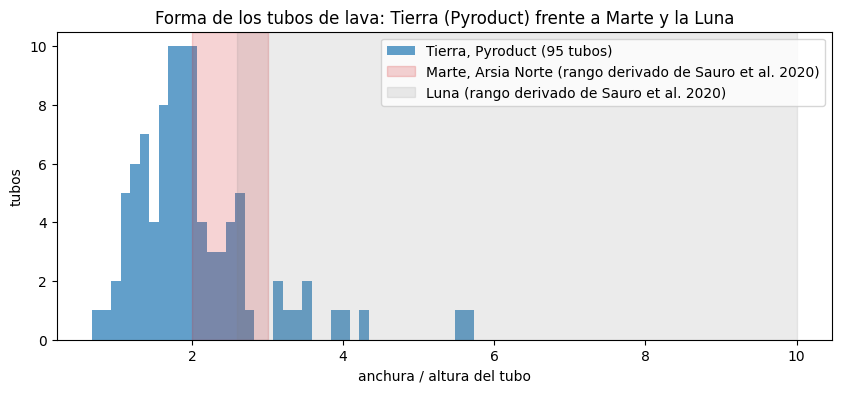

In [7]:
# Pyroduct: anchura y altura de cada sección transversal → anchura/altura mediana por tubo
forma_tubos = pd.DataFrame()
if pyro:
    d_py = f"{TMP}/pyroduct"
    if not os.path.isdir(d_py):
        with zipfile.ZipFile(pyro[0]) as zz:
            zz.extractall(d_py)
    indice = sorted(glob.glob(f"{d_py}/**/*Index*.xlsx", recursive=True))
    if indice:
        idx = pd.read_excel(indice[0])
        print("Índice de Pyroduct:", idx.shape, "· columnas:", list(idx.columns)[:20]); display(idx.head())
    txts = sorted(t for t in glob.glob(f"{d_py}/**/*.txt", recursive=True) if os.path.isfile(t))   # hay carpetas que acaban en «.txt»
    txts = [t for t in txts if not re.search(r"release|license|readme", os.path.basename(t), re.I)]
    print(f"Secciones (.txt): {len(txts)} · ejemplo: {os.path.relpath(txts[0], d_py) if txts else '—'}")
    if txts:
        print(open(txts[0], encoding="latin-1").read()[:400])
    filas = []
    for t in txts:
        try:
            a = pd.read_csv(t, sep=None, engine="python", header=None, comment="#").apply(pd.to_numeric, errors="coerce").dropna(how="all", axis=1).dropna()
            if a.shape[1] < 2 or len(a) < 4:
                continue
            x, y = a.iloc[:, 0].values, a.iloc[:, 1].values
            ancho, alto = float(np.ptp(x)), float(np.ptp(y))
            if ancho > 0 and alto > 0:
                partes_ruta = os.path.relpath(t, d_py).split(os.sep)
                filas.append({"tubo": partes_ruta[-2] if len(partes_ruta) > 1 else "?", "ruta": "/".join(partes_ruta[:-1]),
                              "ancho_m": ancho, "alto_m": alto})
        except Exception:
            pass
    secciones = pd.DataFrame(filas)
    if len(secciones):
        forma_tubos = (secciones.assign(a_h=secciones.ancho_m / secciones.alto_m).groupby(["ruta", "tubo"])
                       .agg(secciones=("a_h", "size"), ancho_mediano_m=("ancho_m", "median"), alto_mediano_m=("alto_m", "median"),
                            ancho_alto_mediana=("a_h", "median")).reset_index().round(2))
        forma_tubos.to_csv(f"{RES}/pyroduct_forma_tubos.csv", index=False)
        print(f"Pyroduct: {len(secciones)} secciones leídas de {len(forma_tubos)} tubos · anchura/altura mediana {secciones.ancho_m.div(secciones.alto_m).median():.2f}")
        display(forma_tubos.sort_values("secciones", ascending=False).head(15))
        # Unir con las cuevas de la tabla por nombre (Corona, Surtshellir, Kazumura, Undara, Valentine…)
        for i, r in TIERRA_CUEVAS.iterrows():
            clave = {"la_corona": "corona", "surtshellir": "surts", "kazumura": "kazumura", "undara": "undara|barker",
                     "valentine_cave": "valentine", "lofthellir": "loft"}.get(r.id)
            m = forma_tubos[forma_tubos.ruta.str.contains(clave, case=False)] if clave else pd.DataFrame()
            if len(m):
                TIERRA_CUEVAS.loc[i, "ancho_alto_pyroduct"] = round(float(m.ancho_alto_mediana.median()), 2)
                TIERRA_CUEVAS.loc[i, "secciones_pyroduct"] = int(m.secciones.sum())
    else:
        print("⚠ No se pudieron leer las secciones de Pyroduct: revisa el ejemplo de arriba y ajusta la lectura")

# Figura: anchura/altura de los tubos de la Tierra frente a los rangos de Sauro et al. (2020) para Marte y la Luna
if len(forma_tubos):
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.hist(forma_tubos.ancho_alto_mediana.clip(0, 12), bins=40, color="tab:blue", alpha=0.7, label=f"Tierra, Pyroduct ({len(forma_tubos)} tubos)")
    ax.axvspan(2, 3, color="tab:red", alpha=0.2, label="Marte, Arsia Norte (rango derivado de Sauro et al. 2020)")
    ax.axvspan(2.6, 10, color="tab:gray", alpha=0.15, label="Luna (rango derivado de Sauro et al. 2020)")
    ax.set_xlabel("anchura / altura del tubo"); ax.set_ylabel("tubos"); ax.legend()
    ax.set_title("Forma de los tubos de lava: Tierra (Pyroduct) frente a Marte y la Luna"); plt.show()
TIERRA_CUEVAS.to_csv(f"{RES}/cuevas_tierra_v2.csv", index=False)

## 5. Comparación por tipo, forma y temperatura interior
- **Compatible**: mismo tipo. Los pozos de fundido de impacto, de tierras altas y las entradas laterales no tienen cueva de la Tierra
  del mismo tipo documentada como análogo: se quedan sin pareja, y eso también es un resultado.
- **Distancia de forma**: |log₁₀(d/D sitio ÷ d/D Tierra)|, hasta 1 (0 = misma proporción; 1 = diez veces distinta).
- **Brecha de temperatura interior**: solo donde hay medida en la Luna.

In [8]:
S = cuevas_sit[["id", "nombre", "cuerpo", "tipo_cueva", "lat", "lon", "diametro_m", "profundidad_m", "d_D", "t_interior_C"]]
T = TIERRA_CUEVAS[["id", "nombre", "tipo_cueva", "verificacion", "d_D", "t_interior_C"]].add_suffix("_t")
pares = S.merge(T, how="cross")
pares = pares[pares.tipo_cueva == pares.tipo_cueva_t].copy()
pares["d_forma"] = np.minimum(np.abs(np.log10(pares.d_D / pares.d_D_t)), 1).round(3)
pares["brecha_t_interior_C"] = (pares.t_interior_C_t - pares.t_interior_C).round(1)
print(f"Pares compatibles (mismo tipo): {len(pares)} · con forma comparable: {pares.d_forma.notna().sum()}")
sin_tipo = cuevas_sit[~cuevas_sit.tipo_cueva.isin(TIERRA_CUEVAS.tipo_cueva)]
print("Sitios-cueva sin cueva de la Tierra del mismo tipo:", sin_tipo.groupby(["cuerpo", "tipo_cueva"]).size().to_dict())

Pares compatibles (mismo tipo): 139 · con forma comparable: 34
Sitios-cueva sin cueva de la Tierra del mismo tipo: {('luna', 'fundido_impacto'): 8, ('luna', 'tierras_altas'): 5, ('marte', 'entrada_lateral'): 8}


## 6. Terreno alrededor (topografía)
Las cuevas de la Tierra se miden con Copernicus GLO-30 igual que en topografia_v2 (círculo de 10 km, pendiente y relieve a ~240 m).
Los sitios-cueva salen de `histogramas_sitios_v2.npz`, que se rellena al ejecutar **topografia_sitios_v2** con los sitios-cueva.
Si todavía no está, esta sección lo avisa y el resto del notebook sigue sin topografía.

In [9]:
COP_URL = "https://copernicus-dem-30m.s3.amazonaws.com"
M_POR_SEG, PIXEL_240_M, LADO_RELIEVE_M = 30.87, 240, 1200
PASO_BIN = 0.25; BINS = np.arange(0, 90 + PASO_BIN, PASO_BIN)
PASO_REL = 1; BINS_REL = np.arange(0, 3000 + PASO_REL, PASO_REL)

def pendiente(z, dy, dx_filas):
    gy, gx = np.gradient(z)
    gx /= np.asarray(dx_filas, dtype="float32")[:, None]; gy /= np.float32(dy)
    np.hypot(gx, gy, out=gx); del gy
    return np.degrees(np.arctan(gx, out=gx), out=gx)

def impar(n):
    n = max(int(round(n)), 3)
    return n if n % 2 else n + 1

def relieve(z, dy, dx):
    tam = (impar(LADO_RELIEVE_M / dy), impar(LADO_RELIEVE_M / dx))
    hueco = ~np.isfinite(z)
    zf = np.where(hueco, np.nanmean(z) if np.isfinite(z).any() else 0, z)
    r = ndimage.maximum_filter(zf, size=tam) - ndimage.minimum_filter(zf, size=tam)
    r[ndimage.maximum_filter(hueco.astype(np.uint8), size=tam) > 0] = np.nan
    return r

def circulo_grados(lon, lat, radio_km):
    rlat = radio_km / 111.32
    return affinity.scale(Point(lon, lat).buffer(rlat, 64), xfact=1 / max(np.cos(np.radians(lat)), 0.05), yfact=1)

def teselas_de(g):
    oeste, sur, este, norte = g.bounds
    return [(la, lo) for la in range(int(np.floor(sur)), int(np.ceil(norte))) for lo in range(int(np.floor(oeste)), int(np.ceil(este)))
            if g.intersects(box(lo, la, lo + 1, la + 1))]

def url_cop(la, lo):
    n = f"Copernicus_DSM_COG_10_{'N' if la >= 0 else 'S'}{abs(la):02d}_00_{'E' if lo >= 0 else 'W'}{abs(lo):03d}_00_DEM"
    return f"{COP_URL}/{n}/{n}.tif"

def procesar(geom, la, lo):
    """Igual que topografia_v2: pendiente y relieve a ~240 m dentro de la geometría (histogramas)."""
    ruta = f"{TMP}/cop_{la}_{lo}.tif"
    with SESION.get(url_cop(la, lo), stream=True, timeout=300) as r:
        if r.status_code in (403, 404):
            return None
        r.raise_for_status()
        with open(ruta, "wb") as f:
            for trozo in r.iter_content(1 << 22):
                f.write(trozo)
    with rasterio.open(ruta) as src:
        z = src.read(1).astype("float32"); tr = src.transform
    os.remove(ruta)
    z[(z < -500) | (z == 0)] = np.nan
    mascara = features.geometry_mask([geom], out_shape=z.shape, transform=tr, invert=True)
    if not mascara.any():
        return None
    lat_filas = tr.f + tr.e * (np.arange(z.shape[0]) + 0.5)
    dx = M_POR_SEG * abs(tr.a) * 3600 * np.cos(np.radians(lat_filas)); dy = M_POR_SEG * abs(tr.e) * 3600
    ky = max(int(round(PIXEL_240_M / dy)), 1); kx = max(int(round(PIXEL_240_M / float(np.mean(dx)))), 1)
    n = (z.shape[0] // ky) * ky, (z.shape[1] // kx) * kx
    with np.errstate(all="ignore"):
        z8 = np.nanmean(z[:n[0], :n[1]].reshape(n[0] // ky, ky, n[1] // kx, kx), axis=(1, 3))
    m8 = mascara[:n[0], :n[1]].reshape(n[0] // ky, ky, n[1] // kx, kx).mean(axis=(1, 3)) >= 0.5
    dx8 = dx[:n[0]].reshape(-1, ky).mean(1) * kx
    s240 = pendiente(z8, dy * ky, dx8); rel = relieve(z8, dy * ky, float(np.mean(dx8)))
    ok, okr = m8 & np.isfinite(s240), m8 & np.isfinite(rel)
    return {"h240": np.histogram(s240[ok], BINS)[0], "hrel": np.histogram(np.clip(rel[okr], 0, BINS_REL[-1] - 0.01), BINS_REL)[0]}

H_T, HR_T = {}, {}
for r in TIERRA_CUEVAS.itertuples():
    geom = circulo_grados(r.lon, r.lat, RADIO_CUEVA_TIERRA_KM)
    h, hr = np.zeros(len(BINS) - 1), np.zeros(len(BINS_REL) - 1)
    for la, lo in teselas_de(geom):
        ruta = f"{CACHE}/topo_{r.id}__{la}_{lo}.npz"
        if not os.path.exists(ruta):
            try:
                out = procesar(geom, la, lo)
                np.savez(ruta, **(out or {"sin_dato": True}))
            except Exception as e:
                print(f"   ⚠ {r.id} {la},{lo}: {e!r}"[:150]); continue
        d = np.load(ruta)
        if "h240" in d.files:
            h += d["h240"]; hr += d["hrel"]
    if h.sum():
        H_T[r.id], HR_T[r.id] = h, hr
print(f"Topografía de las cuevas de la Tierra: {len(H_T)} de {len(TIERRA_CUEVAS)}")

ruta_h = f"{BASE}/04_resultados/topografia_sitios_v2/histogramas_sitios_v2.npz"
HAY_TOPO = False
if os.path.exists(ruta_h):
    hs = np.load(ruta_h)
    H_S = {str(k): (a, b) for k, a, b in zip(hs["ids"], hs["h240"], hs["hrel"])}
    print(f"histogramas_sitios_v2.npz: {len(H_S)} sitios ({sum(k.startswith('cueva-') for k in H_S)} cuevas) · "
          f"modificado {datetime.datetime.fromtimestamp(os.path.getmtime(ruta_h)):%Y-%m-%d %H:%M}")
    faltan = [i for i in cuevas_sit.id if i not in H_S]
    HAY_TOPO = len(faltan) < len(cuevas_sit)
    if faltan:
        print(f"⚠ {len(faltan)} sitios-cueva sin topografía: ejecuta topografia_sitios_v2 (versión nueva) y vuelve a esta sección.")
cdf = lambda h: np.cumsum(h) / h.sum()
ks = lambda a, b: float(np.max(np.abs(cdf(a) - cdf(b))))
pares["d_topo"] = np.nan
if HAY_TOPO:
    for i, r in pares.iterrows():
        if r.id in H_S and r.id_t in H_T:
            a, b = H_S[r.id]
            if a.sum() and b.sum():
                pares.loc[i, "d_topo"] = round((ks(a, H_T[r.id_t]) + ks(b, HR_T[r.id_t])) / 2, 3)
    print(f"Pares con topografía: {pares.d_topo.notna().sum()}")

Topografía de las cuevas de la Tierra: 12 de 12
histogramas_sitios_v2.npz: 160 sitios (63 cuevas) · modificado 2026-10-29 22:58
Pares con topografía: 139


## 7. Mejor cueva de la Tierra para cada sitio-cueva
Entre las cuevas de la Tierra del mismo tipo se elige la de **terreno más parecido** (la topografía es la única medida que tienen
todas); si no hay topografía, la de forma más parecida. **Análogo de cueva** = mismo tipo y topografía ≤ 0,2.
La forma se informa aparte: «forma parecida» si d/D difiere menos de un factor 2 (d_forma ≤ 0,3). Si varias cuevas pasan el umbral
de terreno, se prefiere la de forma parecida.

In [10]:
pares["d_combinada"] = pares[["d_forma", "d_topo"]].mean(axis=1, skipna=True).round(3)
pares["evidencia"] = np.select([pares.d_topo.notna() & pares.d_forma.notna(), pares.d_topo.notna(), pares.d_forma.notna()],
                               ["tipo, forma y terreno", "tipo y terreno", "tipo y forma"], "solo tipo")
pares.to_csv(f"{RES}/similitud_cuevas_v2.csv", index=False)
pares["forma_parecida"] = np.select([pares.d_forma.isna(), pares.d_forma <= 0.3], ["sin medida", "Sí"], "No")
orden = (pares.assign(_v=~pares.verificacion_t.eq("verificada"),
                     _no_ok=~(pares.d_topo <= UMBRAL_TOPO),                  # primero las que ya son análogo por terreno
                     _no_forma=~pares.forma_parecida.eq("Sí"))              # y, entre ellas, las de forma parecida
              .sort_values(["id", "_no_ok", "_no_forma", "d_topo", "d_forma", "_v"], ascending=True, na_position="last"))
mejor = orden.drop_duplicates("id").set_index("id")          # no first(): rellenaría vacíos con otras filas
res = cuevas_sit.merge(mejor[["nombre_t", "verificacion_t", "d_D_t", "d_forma", "forma_parecida", "d_topo", "d_combinada", "evidencia",
                              "t_interior_C_t", "brecha_t_interior_C"]], left_on="id", right_index=True, how="left")
res["analogo_cueva"] = np.select([res.nombre_t.isna(), res.d_topo.notna() & (res.d_topo <= UMBRAL_TOPO), res.d_topo.notna()],
                                 ["sin cueva del mismo tipo", "Sí", "mismo tipo, terreno distinto"], "mismo tipo (sin topografía)")
res.to_csv(f"{RES}/cuevas_sitios_v2.csv", index=False)
cols = ["nombre", "tipo_cueva", "diametro_m", "profundidad_m", "d_D", "nombre_t", "d_D_t", "forma_parecida", "d_topo", "analogo_cueva"]
for cuerpo in ["luna", "marte"]:
    print(cuerpo.capitalize()); display(res[res.cuerpo == cuerpo].sort_values(["tipo_cueva", "d_topo"])[cols])
print(res.groupby(["cuerpo", "analogo_cueva"]).size())
print("Temperatura interior: pozos lunares medidos frente a las cuevas de la Tierra del mismo tipo (de menor a mayor brecha)")
display(pares[pares.t_interior_C.notna() & pares.t_interior_C_t.notna()].assign(_b=lambda d: d.brecha_t_interior_C.abs())
        .sort_values(["nombre", "_b"])[["nombre", "t_interior_C", "nombre_t", "t_interior_C_t", "brecha_t_interior_C", "d_topo"]])

Luna


,nombre,tipo_cueva,diametro_m,profundidad_m,d_D,nombre_t,d_D_t,forma_parecida,d_topo,analogo_cueva
21,Copernicus LB3,fundido_impacto,385.0,66.0,0.171,NaN,NaN,NaN,NaN,sin cueva del mismo tipo
22,Crookes 1,fundido_impacto,213.0,17.0,0.080,NaN,NaN,NaN,NaN,sin cueva del mismo tipo
23,King 28,fundido_impacto,156.0,22.0,0.141,NaN,NaN,NaN,NaN,sin cueva del mismo tipo
24,Tharp 1a,fundido_impacto,116.0,23.0,0.198,NaN,NaN,NaN,NaN,sin cueva del mismo tipo
25,Jackson 1c,fundido_impacto,95.0,15.0,0.158,NaN,NaN,NaN,NaN,sin cueva del mismo tipo
26,Tycho 5b,fundido_impacto,77.0,15.0,0.195,NaN,NaN,NaN,NaN,sin cueva del mismo tipo
27,Weiner F 1,fundido_impacto,63.0,22.0,0.349,NaN,NaN,NaN,NaN,sin cueva del mismo tipo
28,Stevinus 1,fundido_impacto,60.0,16.0,0.267,NaN,NaN,NaN,NaN,sin cueva del mismo tipo
12,Mare Insularum Pit,pozo_colapso,315.0,63.0,0.200,Jubas del norte del Golán,NaN,sin medida,0.376,"mismo tipo, terreno distinto"
6,Runge Pit,pozo_colapso,14.0,5.0,0.357,Cráteres de colapso del Kīlauea (Devil's Throat),1.065,No,0.417,"mismo tipo, terreno distinto"


Marte


,nombre,tipo_cueva,diametro_m,profundidad_m,d_D,nombre_t,d_D_t,forma_parecida,d_topo,analogo_cueva
29,CC0093,entrada_lateral,NaN,NaN,NaN,NaN,NaN,NaN,NaN,sin cueva del mismo tipo
30,CC0713,entrada_lateral,NaN,NaN,NaN,NaN,NaN,NaN,NaN,sin cueva del mismo tipo
31,CC0727,entrada_lateral,NaN,NaN,NaN,NaN,NaN,NaN,NaN,sin cueva del mismo tipo
32,CC0730,entrada_lateral,NaN,NaN,NaN,NaN,NaN,NaN,NaN,sin cueva del mismo tipo
33,CC0742,entrada_lateral,NaN,NaN,NaN,NaN,NaN,NaN,NaN,sin cueva del mismo tipo
34,CC0832,entrada_lateral,NaN,NaN,NaN,NaN,NaN,NaN,NaN,sin cueva del mismo tipo
35,CC0843,entrada_lateral,NaN,NaN,NaN,NaN,NaN,NaN,NaN,sin cueva del mismo tipo
36,CC0846,entrada_lateral,NaN,NaN,NaN,NaN,NaN,NaN,NaN,sin cueva del mismo tipo
44,CC0831,fractura,NaN,NaN,NaN,"Fisuras y pozos tectónicos de Krafla, Islandia",NaN,sin medida,0.066,Sí
39,CC0803,fractura,NaN,NaN,NaN,"Fisuras y pozos tectónicos de Krafla, Islandia",NaN,sin medida,0.169,Sí


cuerpo  analogo_cueva               
luna    Sí                               2
        mismo tipo, terreno distinto    14
        sin cueva del mismo tipo        13
marte   Sí                               5
        mismo tipo, terreno distinto    21
        sin cueva del mismo tipo         8
dtype: int64
Temperatura interior: pozos lunares medidos frente a las cuevas de la Tierra del mismo tipo (de menor a mayor brecha)


,nombre,t_interior_C,nombre_t,t_interior_C_t,brecha_t_interior_C,d_topo
64,Mare Ingenii Pit,16.9,"Tubos de lava del Mauna Loa (HI-SEAS), Hawái",17.4,0.5,0.886
65,Mare Ingenii Pit,16.9,"Kazumura Cave, Hawái",20.9,4.0,0.902
60,Mare Ingenii Pit,16.9,La Corona (Cueva de los Verdes / Túnel de la A...,25.0,8.1,0.915
61,Mare Ingenii Pit,16.9,"Surtshellir–Stefánshellir (Hallmundarhraun), I...",-3.9,-20.8,0.616
62,Mare Ingenii Pit,16.9,"Lofthellir (tubo de lava con hielo), Islandia",-5.3,-22.2,0.559
28,Mare Tranquillitatis Pit,16.9,"Tubos de lava del Mauna Loa (HI-SEAS), Hawái",17.4,0.5,0.787
29,Mare Tranquillitatis Pit,16.9,"Kazumura Cave, Hawái",20.9,4.0,0.788
24,Mare Tranquillitatis Pit,16.9,La Corona (Cueva de los Verdes / Túnel de la A...,25.0,8.1,0.828
25,Mare Tranquillitatis Pit,16.9,"Surtshellir–Stefánshellir (Hallmundarhraun), I...",-3.9,-20.8,0.455
26,Mare Tranquillitatis Pit,16.9,"Lofthellir (tubo de lava con hielo), Islandia",-5.3,-22.2,0.428


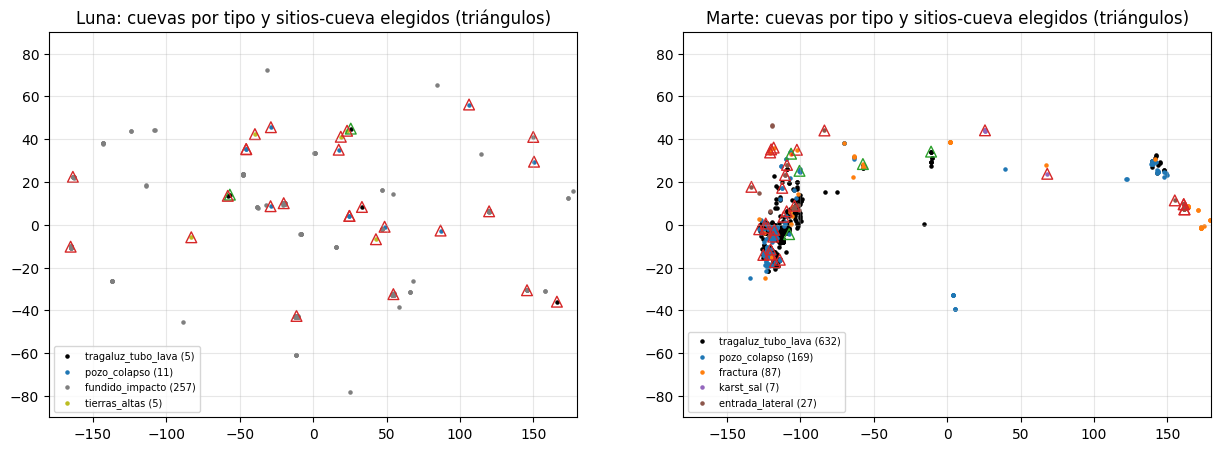

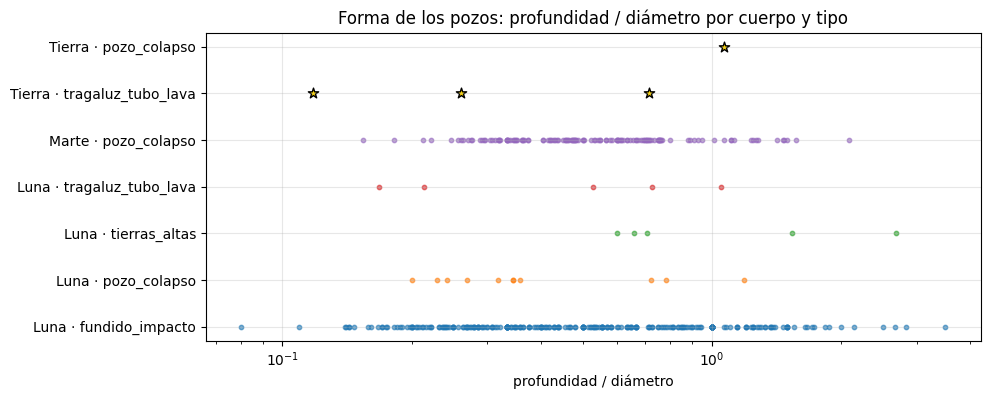

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
for ax, (cuerpo, cat) in zip(axs, (("luna", luna), ("marte", marte))):
    for tipo, color in (("tragaluz_tubo_lava", "black"), ("pozo_colapso", "tab:blue"), ("fractura", "tab:orange"),
                        ("karst_sal", "tab:purple"), ("fundido_impacto", "tab:gray"), ("tierras_altas", "tab:olive"), ("entrada_lateral", "tab:brown")):
        c = cat[cat.tipo_cueva == tipo]
        if len(c):
            ax.scatter(c.lon, c.lat, s=5, c=color, label=f"{tipo} ({len(c)})")
    s = res[res.cuerpo == cuerpo]
    ax.scatter(s.lon, s.lat, s=60, marker="^", facecolors="none", edgecolors=np.where(s.analogo_cueva == "Sí", "tab:green", "tab:red"))
    ax.set_xlim(-180, 180); ax.set_ylim(-90, 90); ax.grid(alpha=0.3); ax.legend(fontsize=7, loc="lower left")
    ax.set_title(f"{cuerpo.capitalize()}: cuevas por tipo y sitios-cueva elegidos (triángulos)")
plt.show()

d = pd.concat([luna.assign(cuerpo="Luna"), marte.assign(cuerpo="Marte")])
d = d[d.d_D.between(0.01, 5)]
fig, ax = plt.subplots(figsize=(10, 4))
for (cuerpo, tipo), g in d.groupby(["cuerpo", "tipo_cueva"]):
    if len(g) >= 3:
        ax.scatter(g.d_D, [f"{cuerpo} · {tipo}"] * len(g), s=10, alpha=0.6)
t = TIERRA_CUEVAS.dropna(subset=["d_D"])
ax.scatter(t.d_D, ["Tierra · " + x for x in t.tipo_cueva], s=60, marker="*", c="gold", edgecolors="k")
ax.set_xscale("log"); ax.set_xlabel("profundidad / diámetro"); ax.grid(alpha=0.3)
ax.set_title("Forma de los pozos: profundidad / diámetro por cuerpo y tipo"); plt.show()

## 8. Capa para la web y registro

In [12]:
def limpio(v):
    if isinstance(v, (float, np.floating)): return None if not np.isfinite(v) else round(float(v), 3)
    if isinstance(v, np.integer): return int(v)
    if isinstance(v, np.bool_): return bool(v)
    return v

top3 = orden.groupby("id").head(3)
campos_s = ["nombre", "cuerpo", "tipo_cueva", "lat", "lon", "diametro_m", "profundidad_m", "d_D", "saliente", "evidencia_tubo",
            "t_interior_C", "fuente_t_interior", "codigo", "prioridad", "comentario", "analogo_cueva"]
salida = {"version": VERSION,
          "tipos": {"tragaluz_tubo_lava": "abertura en el techo de un tubo de lava", "pozo_colapso": "pozo de colapso sin tubo visible",
                    "fractura": "pozo o grieta sobre fracturas", "karst_sal": "cueva de disolución en sales",
                    "fundido_impacto": "pozo en fundido de impacto (sin análogo conocido)", "tierras_altas": "pozo en tierras altas lunares (sin análogo conocido)",
                    "entrada_lateral": "entrada en un acantilado (sin análogo en la tabla)", "cueva_hielo": "cueva en hielo"},
          "unidades": {"d_D": "profundidad / diámetro", "d_forma": "|log10(d/D sitio ÷ d/D Tierra)|, 0–1",
                       "d_topo": "media de KS de pendiente y relieve (como topografia_sitios_v2)", "t_interior_C": "°C"},
          "sitios": {r["id"]: {**{k: limpio(r.get(k)) for k in campos_s if k in r},
                               "parejas": [{k: limpio(p[k]) for k in ("id_t", "nombre_t", "verificacion_t", "d_D_t", "d_forma", "forma_parecida", "d_topo",
                                                                      "d_combinada", "evidencia", "t_interior_C_t", "brecha_t_interior_C")}
                                           for p in top3[top3.id == r["id"]].to_dict("records")]}
                     for r in res.to_dict("records")},
          "tierra": {r["id"]: {k: limpio(v) for k, v in r.items() if k != "id"} for r in TIERRA_CUEVAS.to_dict("records")},
          "nota": "geometría de los sitios en 06_web/sitios_cuevas_v0/sitios_cuevas.geojson (unir por id)"}
json.dump(salida, open(f"{WEB}/cuevas.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1, allow_nan=False)
entrada = json.load(open(f"{BASE}/06_web/manifest.json", encoding="utf-8"))
entrada.setdefault("capas", {})["cuevas_v2"] = {"version": VERSION, "carpeta": VERSION, "archivo": f"{VERSION}/cuevas.json",
                                                "sitios": "sitios_cuevas_v0/sitios_cuevas.geojson"}
json.dump(entrada, open(f"{BASE}/06_web/manifest.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

cuenta = lambda c, v: int(((res.cuerpo == c) & (res.analogo_cueva == v)).sum())
registro = {"version": VERSION, "fecha": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="minutes"),
            "fuentes": {"luna": "LROC Lunar Pit Atlas (Wagner y Robinson 2021)", "luna_nubes": "Zenodo 6622042 (Wagner y Robinson 2022)",
                        "luna_t_interior": "Horvath et al. 2022, GRL, doi:10.1029/2022GL099710", "luna_tubo": "Carrer et al. 2024, Nature Astronomy",
                        "marte": "Mars Global Cave Candidate Catalog (Cushing)", "marte_profundidad": "PITS, Zenodo 8308454",
                        "tierra_forma": "Pyroduct Digital Catalog v3.0, Zenodo 23456401; Sauro et al. 2020",
                        "tierra_topografia": "Copernicus DEM GLO-30 (AWS)", "tierra_cuevas": "ficha de análogos"},
            "parametros": {"max_por_tipo_marte": MAX_POR_TIPO_MARTE, "max_fundido_luna": MAX_FUNDIDO_LUNA, "umbral_topo": UMBRAL_TOPO,
                           "radio_cueva_tierra_km": RADIO_CUEVA_TIERRA_KM, "t_sombra_pozo_K": T_SOMBRA_POZO_K},
            "metricas": {"sitios_cueva_luna": int((res.cuerpo == "luna").sum()), "sitios_cueva_marte": int((res.cuerpo == "marte").sum()),
                         "con_topografia": bool(HAY_TOPO),
                         **{f"{c}_{slug(v).replace('-', '_')}": cuenta(c, v) for c in ("luna", "marte")
                            for v in ("Sí", "mismo tipo, terreno distinto", "mismo tipo (sin topografía)", "sin cueva del mismo tipo")},
                         "tubos_pyroduct": int(len(forma_tubos))},
            "limitaciones": ["la clase de cueva se deduce del terreno y de los rasgos del atlas (Luna) o del código del catálogo (Marte)",
                             "la forma solo compara profundidad/diámetro; en la Tierra hay pocas medidas publicadas de colapsos",
                             "temperatura interior: en la Luna solo medida en Mare Tranquillitatis y Mare Ingenii; en la Tierra se aproxima con la superficie media (MODIS)",
                             "coordenadas de varias cuevas de la Tierra aproximadas (ver ficha)"]}
json.dump(registro, open(f"{RES}/registro_{VERSION}.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2, default=str)
print("✅ Exportado:", json.dumps(registro["metricas"], ensure_ascii=False, indent=1))

✅ Exportado: {
 "sitios_cueva_luna": 29,
 "sitios_cueva_marte": 34,
 "con_topografia": true,
 "luna_si": 2,
 "luna_mismo_tipo_terreno_distinto": 14,
 "luna_mismo_tipo_sin_topografia": 0,
 "luna_sin_cueva_del_mismo_tipo": 13,
 "marte_si": 5,
 "marte_mismo_tipo_terreno_distinto": 21,
 "marte_mismo_tipo_sin_topografia": 0,
 "marte_sin_cueva_del_mismo_tipo": 8,
 "tubos_pyroduct": 95
}
